# NumPy y pandas · pandas avanzado

Combinar, reestructurar, agrupar, limpiar y analizar datos con pandas: `merge`, `concat`, `pivot_table`, `melt`, `groupby`, series temporales, `cut`/`qcut`, vectorización y `MultiIndex`. Los datos de una pequeña tienda (clientes, productos y pedidos) se generan en el propio notebook con una semilla fija.

In [1]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(7)
clientes = pd.DataFrame({
    "id_cliente": range(1, 9),
    "nombre": ["Ana", "Luis", "Marta", "Pedro", "Lucía", "Jorge", "Elena", "Raúl"],
    "region": ["Norte", "Sur", "Norte", "Este", "Sur", "Oeste", "Este", "Norte"],
    "edad": [34, 52, 23, 41, 67, 29, 45, 18],
})
productos = pd.DataFrame({
    "producto": ["portátil", "ratón", "teclado", "monitor", "auriculares"],
    "categoria": ["informática", "accesorios", "accesorios", "informática", "audio"],
    "precio": [899.0, 19.9, 49.5, 229.0, 79.0],
})
n = 60
pedidos = pd.DataFrame({
    "id_pedido": range(1001, 1001 + n),
    # Raúl (8) no compra y los clientes 9 y 10 no están dados de alta
    "id_cliente": rng.choice([1, 2, 3, 4, 5, 6, 7, 9, 10], size=n),
    "producto": rng.choice(productos["producto"], size=n, p=[0.1, 0.3, 0.25, 0.15, 0.2]),
    "unidades": rng.integers(1, 5, size=n),
    "fecha": pd.Timestamp("2025-01-01") + pd.to_timedelta(rng.integers(0, 120, size=n), unit="D"),
})
print(clientes.shape, productos.shape, pedidos.shape)
print(pedidos.head())

(8, 4) (5, 3) (60, 5)
   id_pedido  id_cliente  producto  unidades      fecha
0       1001          10   teclado         3 2025-04-27
1       1002           6     ratón         1 2025-01-02
2       1003           7  portátil         4 2025-04-14
3       1004          10     ratón         4 2025-03-17
4       1005           6   monitor         3 2025-02-28


## 1. Combinar tablas con `merge`

Unir los pedidos con los clientes con `merge` de tipo `inner`, `left` y `outer`, y usar `indicator=True` para encontrar los clientes sin pedidos y los pedidos de clientes desconocidos. Después crear la tabla `detalle` con los pedidos de clientes conocidos, sus productos y el importe de cada pedido, comprobando con `validate` que cada pedido casa con un único cliente y producto.

In [2]:
interior = pedidos.merge(clientes, on="id_cliente", how="inner")
izquierda = pedidos.merge(clientes, on="id_cliente", how="left")
exterior = pedidos.merge(clientes, on="id_cliente", how="outer", indicator=True)
print(len(interior), len(izquierda), len(exterior))
print(exterior["_merge"].value_counts())
print(exterior.loc[exterior["_merge"] == "right_only", ["id_cliente", "nombre"]])
print(sorted(exterior.loc[exterior["_merge"] == "left_only", "id_cliente"].unique().tolist()))
assert len(interior) == pedidos["id_cliente"].isin(clientes["id_cliente"]).sum()
assert len(izquierda) == len(pedidos) and izquierda["nombre"].isna().sum() == len(pedidos) - len(interior)

detalle = interior.merge(productos, on="producto", validate="many_to_one")
detalle["importe"] = detalle["unidades"] * detalle["precio"]
print(detalle[["id_pedido", "nombre", "producto", "unidades", "importe"]].head())

41 60 61
_merge
both          41
left_only     19
right_only     1
Name: count, dtype: int64
    id_cliente nombre
41           8   Raúl
[9, 10]
   id_pedido nombre  producto  unidades  importe
0       1002  Jorge     ratón         1     19.9
1       1003  Elena  portátil         4   3596.0
2       1005  Jorge   monitor         3    687.0
3       1006  Elena     ratón         2     39.8
4       1008  Marta  portátil         3   2697.0


## 2. `concat` y `join`

Apilar las ventas de enero y febrero una debajo de otra con `concat` (con `keys` para saber de qué mes viene cada fila) y ponerlas una al lado de otra por producto. Después unir por índice con `join` el importe vendido en cada región con su objetivo y marcar las regiones que lo cumplen.

In [3]:
enero = pd.DataFrame({"producto": ["ratón", "teclado", "monitor"], "unidades": [10, 4, 1]})
febrero = pd.DataFrame({"producto": ["ratón", "monitor", "portátil"], "unidades": [7, 2, 1]})
print(pd.concat([enero, febrero], keys=["enero", "febrero"], names=["mes", "fila"]))
lado_a_lado = pd.concat([enero.set_index("producto"), febrero.set_index("producto")], axis=1, keys=["enero", "febrero"])
print(lado_a_lado.fillna(0).astype(int))
assert pd.concat([enero, febrero], ignore_index=True)["unidades"].sum() == enero["unidades"].sum() + febrero["unidades"].sum()

ventas_region = detalle.groupby("region")[["importe"]].sum()
objetivos = pd.DataFrame({"objetivo": [6000, 5000, 4000, 2500]}, index=pd.Index(["Norte", "Sur", "Este", "Oeste"], name="region"))
informe = ventas_region.join(objetivos)
informe["cumplido"] = informe["importe"] >= informe["objetivo"]
print(informe)

              producto  unidades
mes     fila                    
enero   0        ratón        10
        1      teclado         4
        2      monitor         1
febrero 0        ratón         7
        1      monitor         2
        2     portátil         1
            enero  febrero
         unidades unidades
producto                  
ratón          10        7
teclado         4        0
monitor         1        2
portátil        0        1
        importe  objetivo  cumplido
region                             
Este     5306.5      4000      True
Norte    3647.0      6000     False
Oeste    2772.2      2500      True
Sur      7239.7      5000      True


## 3. Tablas dinámicas con `pivot_table`

Crear una tabla dinámica con el importe total por región (filas) y categoría (columnas), rellenando con 0 las combinaciones sin ventas y con los totales de filas y columnas (`margins`). Crear otra con el número de pedidos y las unidades medias de cada mes.

In [4]:
tabla = detalle.pivot_table(index="region", columns="categoria", values="importe", aggfunc="sum",
                            fill_value=0, margins=True, margins_name="Total")
print(tabla.round(1))
assert np.isclose(tabla.loc["Total", "Total"], detalle["importe"].sum())
assert np.isclose(tabla.loc["Norte", "audio"], detalle.query("region == 'Norte' and categoria == 'audio'")["importe"].sum())

detalle["mes"] = detalle["fecha"].dt.to_period("M")
print(detalle.pivot_table(index="mes", values=["id_pedido", "unidades"], aggfunc={"id_pedido": "count", "unidades": "mean"}).round(2))

categoria  accesorios   audio  informática    Total
region                                             
Este            495.5   316.0       4495.0   5306.5
Norte           397.0   553.0       2697.0   3647.0
Oeste           208.2    79.0       2485.0   2772.2
Sur            1100.7   711.0       5428.0   7239.7
Total          2201.4  1659.0      15105.0  18965.4
         id_pedido  unidades
mes                         
2025-01          9      2.22
2025-02          9      2.11
2025-03          9      3.00
2025-04         14      3.29


## 4. De ancho a largo con `melt`

Pasar una tabla ancha de notas (una columna por trimestre) a formato largo con `melt`, que es el que necesitan `groupby` y muchas librerías de gráficos. Calcular la media de cada alumno y de cada trimestre y volver al formato ancho con `pivot`, comprobando que se recupera la tabla original.

In [5]:
notas = pd.DataFrame({"alumno": ["Ana", "Luis", "Marta"], "T1": [7.5, 5.0, 9.0], "T2": [8.0, 6.5, 8.5], "T3": [6.5, 7.0, 9.5]})
largo = notas.melt(id_vars="alumno", var_name="trimestre", value_name="nota")
print(largo)
print(largo.groupby("alumno")["nota"].mean().round(2).to_dict(), largo.groupby("trimestre")["nota"].mean().round(2).to_dict())
ancho = largo.pivot(index="alumno", columns="trimestre", values="nota").reset_index().rename_axis(columns=None)
print(ancho)
assert ancho.equals(notas)

  alumno trimestre  nota
0    Ana        T1   7.5
1   Luis        T1   5.0
2  Marta        T1   9.0
3    Ana        T2   8.0
4   Luis        T2   6.5
5  Marta        T2   8.5
6    Ana        T3   6.5
7   Luis        T3   7.0
8  Marta        T3   9.5
{'Ana': 7.33, 'Luis': 6.17, 'Marta': 9.0} {'T1': 7.17, 'T2': 7.67, 'T3': 7.67}
  alumno   T1   T2   T3
0    Ana  7.5  8.0  6.5
1   Luis  5.0  6.5  7.0
2  Marta  9.0  8.5  9.5


## 5. Agrupar con `agg`

Para cada región calcular con agregaciones con nombre el número de pedidos, las unidades totales, el importe total y medio y el producto más vendido, ordenando por importe. Calcular también el mínimo, el máximo, la media y la suma del importe de cada categoría.

In [6]:
resumen = detalle.groupby("region").agg(
    pedidos=("id_pedido", "count"),
    unidades=("unidades", "sum"),
    importe_total=("importe", "sum"),
    importe_medio=("importe", "mean"),
    mas_vendido=("producto", lambda s: s.value_counts().idxmax()),
).sort_values("importe_total", ascending=False)
print(resumen.round(1))
norte = detalle[detalle["region"] == "Norte"]
assert resumen.loc["Norte", "pedidos"] == len(norte) and np.isclose(resumen.loc["Norte", "importe_total"], norte["importe"].sum())
print(detalle.groupby("categoria")["importe"].agg(["min", "max", "mean", "sum"]).round(1))

        pedidos  unidades  importe_total  importe_medio mas_vendido
region                                                             
Sur          18        54         7239.7          402.2     teclado
Este          7        22         5306.5          758.1    portátil
Norte        10        24         3647.0          364.7       ratón
Oeste         6        12         2772.2          462.0       ratón
               min     max    mean      sum
categoria                                  
accesorios    19.9   198.0    95.7   2201.4
audio         79.0   316.0   184.3   1659.0
informática  229.0  3596.0  1678.3  15105.0


## 6. `transform` y `apply` en grupos

Añadir a cada pedido el porcentaje que supone sobre el gasto total de su cliente con `transform`, que devuelve un valor por fila alineado con la tabla original. Obtener con `apply` los dos pedidos más caros de cada cliente (una tabla por grupo) y comprobarlo ordenando y quedándose con las dos primeras filas de cada grupo.

In [7]:
total_cliente = detalle.groupby("id_cliente")["importe"].transform("sum")
detalle["pct_cliente"] = 100 * detalle["importe"] / total_cliente
print(detalle[["nombre", "importe", "pct_cliente"]].head().round(1))
assert len(total_cliente) == len(detalle) and np.allclose(detalle.groupby("id_cliente")["pct_cliente"].sum(), 100)

top2 = detalle.groupby("nombre")[["id_pedido", "producto", "importe"]].apply(lambda g: g.nlargest(2, "importe"))
print(top2.head(6))
alternativa = detalle.sort_values("importe", ascending=False).groupby("nombre").head(2)
assert set(top2["id_pedido"]) == set(alternativa["id_pedido"])

  nombre  importe  pct_cliente
0  Jorge     19.9          0.7
1  Elena   3596.0         92.4
2  Jorge    687.0         24.8
3  Elena     39.8          1.0
4  Marta   2697.0         87.7
           id_pedido     producto  importe
nombre                                    
Ana    32       1048  auriculares    316.0
       5        1009  auriculares    158.0
Elena  1        1003     portátil   3596.0
       24       1037      teclado    198.0
Jorge  25       1038     portátil   1798.0
       2        1005      monitor    687.0


## 7. Limpieza de datos

Limpiar una tabla de altas con problemas típicos: espacios y mayúsculas en los nombres, correos en mayúsculas o sin dominio válido, importes como texto con coma decimal o valores no numéricos, fechas en dos formatos o imposibles, nulos y filas duplicadas. Convertir cada columna a su tipo, eliminar duplicados y filas sin nombre y rellenar los importes que faltan con la mediana.

In [8]:
sucio = pd.DataFrame({
    "nombre": ["  ana garcía", "LUIS PÉREZ ", "marta   ruiz", "Ana García", None, "pedro gil"],
    "email": ["ANA@correo.es", "luis@correo.es", "marta@correo", "ana@correo.es", "sin@correo.es", "pedro@correo.es"],
    "importe": ["12,50", "7", "n/d", "12,50", "3,25", ""],
    "alta": ["2025-01-15", "2025-02-30", "2025-03-01", "2025-01-15", "2025-04-10", "15/05/2025"],
})
limpio = sucio.copy()
limpio["nombre"] = limpio["nombre"].str.strip().str.replace(r"\s+", " ", regex=True).str.title()
limpio["email"] = limpio["email"].str.lower()
limpio["email_valido"] = limpio["email"].str.fullmatch(r"[\w.]+@\w+\.\w+")
limpio["importe"] = pd.to_numeric(limpio["importe"].str.replace(",", "."), errors="coerce")
# primero el formato ISO y, donde falle, el día/mes/año; el 30 de febrero queda como NaT
limpio["alta"] = (pd.to_datetime(limpio["alta"], format="%Y-%m-%d", errors="coerce")
                  .fillna(pd.to_datetime(limpio["alta"], format="%d/%m/%Y", errors="coerce")))
print(limpio.isna().sum().to_dict())
limpio = limpio.drop_duplicates().dropna(subset=["nombre"]).reset_index(drop=True)
limpio["importe"] = limpio["importe"].fillna(limpio["importe"].median())
print(limpio)
print(limpio.dtypes.astype(str).to_dict())
assert limpio["nombre"].tolist() == ["Ana García", "Luis Pérez", "Marta Ruiz", "Pedro Gil"]
assert limpio["email_valido"].tolist() == [True, True, False, True]

{'nombre': 1, 'email': 0, 'importe': 2, 'alta': 1, 'email_valido': 0}
       nombre            email  importe       alta  email_valido
0  Ana García    ana@correo.es    12.50 2025-01-15          True
1  Luis Pérez   luis@correo.es     7.00        NaT          True
2  Marta Ruiz     marta@correo     9.75 2025-03-01         False
3   Pedro Gil  pedro@correo.es     9.75 2025-05-15          True
{'nombre': 'str', 'email': 'str', 'importe': 'float64', 'alta': 'datetime64[us]', 'email_valido': 'bool'}


## 8. Series temporales

Generar las ventas diarias de una tienda durante 2025 (tendencia creciente, más ventas los fines de semana y ruido) y calcular: el total semanal y mensual con `resample`, la media móvil de 7 días con `rolling`, y la diferencia con el día anterior y la variación porcentual respecto al mismo día de la semana anterior con `shift`. Dibujar las ventas y la media móvil.

2025-01-05    570.4
2025-01-12    787.9
2025-01-19    785.5
Freq: W-SUN, Name: ventas, dtype: float64
2025-01-31    3505.2
2025-02-28    3304.0
2025-03-31    3838.5
2025-04-30    3850.8
Freq: ME, Name: ventas, dtype: float64
            ventas   ayer  diferencia  pct_semana  media7
2025-01-06    98.7  136.1       -37.4         NaN     NaN
2025-01-07    80.8   98.7       -17.9         NaN   107.1
2025-01-08    98.8   80.8        18.0       -17.9   104.0
2025-01-09    92.7   98.8        -6.1        24.3   106.6
2025-01-10   134.7   92.7        42.0        28.9   110.9


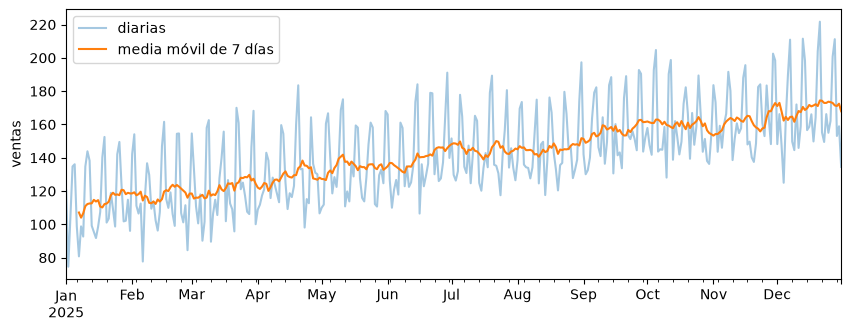

In [9]:
import matplotlib.pyplot as plt

dias = pd.date_range("2025-01-01", "2025-12-31", freq="D")
rng = np.random.default_rng(3)
ventas = pd.Series(np.linspace(100, 160, len(dias)) + np.where(dias.day_of_week >= 5, 40, 0) + rng.normal(0, 10, len(dias)),
                   index=dias, name="ventas").round(1)
semanal, mensual = ventas.resample("W").sum(), ventas.resample("ME").sum()
print(semanal.head(3).round(1), mensual.head(4).round(1), sep="\n")
media7 = ventas.rolling(7).mean()
cambios = pd.DataFrame({"ventas": ventas, "ayer": ventas.shift(1), "diferencia": ventas - ventas.shift(1),
                        "pct_semana": 100 * (ventas / ventas.shift(7) - 1), "media7": media7}).round(1)
print(cambios.iloc[5:10])
assert np.isclose(media7.iloc[6], ventas.iloc[:7].mean()) and np.isclose(mensual.sum(), ventas.sum())
assert len(mensual) == 12 and cambios["ayer"].iloc[1:].tolist() == ventas.iloc[:-1].tolist()

fig, eje = plt.subplots(figsize=(10, 3.5))
ventas.plot(ax=eje, alpha=0.4, label="diarias")
media7.plot(ax=eje, label="media móvil de 7 días")
eje.set_ylabel("ventas")
eje.legend()
plt.show()

## 9. Discretizar con `cut` y `qcut`

Clasificar a los clientes en tramos de edad fijos con `cut` (joven hasta 29, adulto de 30 a 59 y mayor desde 60) y los pedidos en cuatro grupos del mismo tamaño según su importe con `qcut`. Contar cuántos hay en cada tramo y calcular el importe que gasta cada tramo de edad.

In [10]:
clientes["tramo"] = pd.cut(clientes["edad"], bins=[0, 30, 60, 120], labels=["joven", "adulto", "mayor"], right=False)
print(clientes[["nombre", "edad", "tramo"]])
esperado = ["joven" if e < 30 else "adulto" if e < 60 else "mayor" for e in clientes["edad"]]
assert clientes["tramo"].astype(str).tolist() == esperado

detalle["cuartil"] = pd.qcut(detalle["importe"], q=4, labels=["Q1", "Q2", "Q3", "Q4"])
print(detalle.groupby("cuartil", observed=True)["importe"].agg(["count", "min", "max"]))
gasto = detalle.merge(clientes[["id_cliente", "tramo"]], on="id_cliente").groupby("tramo", observed=True)["importe"].sum()
print(gasto)
assert np.isclose(gasto.sum(), detalle["importe"].sum())

  nombre  edad   tramo
0    Ana    34  adulto
1   Luis    52  adulto
2  Marta    23   joven
3  Pedro    41  adulto
4  Lucía    67   mayor
5  Jorge    29   joven
6  Elena    45  adulto
7   Raúl    18   joven
         count    min     max
cuartil                      
Q1          11   19.9    59.7
Q2          10   79.0   148.5
Q3          12  158.0   316.0
Q4           8  687.0  3596.0
tramo
joven      5846.3
adulto    10886.7
mayor      2232.4
Name: importe, dtype: float64


## 10. Vectorización frente a `apply`

Calcular el precio final de cada línea de una tabla de 100 000 pedidos (unidades × precio, con un 21 % de IVA y un 10 % de descuento si el importe pasa de 500 €) de tres formas: con `apply` fila a fila, con una comprensión de listas y vectorizado con `np.where`. Comprobar que coinciden y medir los tiempos con `timeit`.

In [11]:
import timeit

rng = np.random.default_rng(10)
grande = pd.DataFrame({"unidades": rng.integers(1, 5, 100_000), "precio": rng.choice(productos["precio"], 100_000)})

def final_fila(fila):
    importe = fila["unidades"] * fila["precio"]
    return importe * 1.21 * (0.9 if importe > 500 else 1)

def con_apply(df):
    return df.apply(final_fila, axis=1)

def con_comprension(df):
    return pd.Series([u * p * 1.21 * (0.9 if u * p > 500 else 1) for u, p in zip(df["unidades"], df["precio"])], index=df.index)

def vectorizado(df):
    importe = df["unidades"] * df["precio"]
    return importe * 1.21 * np.where(importe > 500, 0.9, 1)

resultados = [f(grande) for f in (con_apply, con_comprension, vectorizado)]
assert all(np.allclose(r, resultados[-1]) for r in resultados)
for f in (con_apply, con_comprension, vectorizado):
    print(f"{f.__name__:16}{min(timeit.repeat(lambda: f(grande), repeat=2, number=1)) * 1000:9.1f} ms")

con_apply           500.0 ms
con_comprension      27.9 ms
vectorizado           1.1 ms


## 11. Índices jerárquicos con `MultiIndex`

Agrupar el detalle por región y categoría para obtener una tabla con índice de dos niveles. Seleccionar con `loc` por el primer nivel y por los dos, con `xs` por el segundo nivel y con `pd.IndexSlice` varias regiones de una categoría; intercambiar los niveles con `swaplevel`, pasar las categorías a columnas con `unstack` y volver con `stack`.

In [12]:
multi = detalle.groupby(["region", "categoria"])[["importe", "unidades"]].sum()
print(multi.index.nlevels, multi.index.names)
print(multi.loc["Norte"])
print(multi.loc[("Sur", "accesorios")].to_dict())
print(multi.xs("audio", level="categoria"))
print(multi.loc[pd.IndexSlice[["Este", "Oeste"], "informática"], :])
print(multi.swaplevel().sort_index().head(4))
ancho = multi["importe"].unstack(fill_value=0)
print(ancho)
vuelta = ancho.stack()
assert vuelta[vuelta != 0].sort_index().equals(multi["importe"].sort_index())

2 ['region', 'categoria']
             importe  unidades
categoria                     
accesorios     397.0        14
audio          553.0         7
informática   2697.0         3
{'importe': 1100.7, 'unidades': 33.0}
        importe  unidades
region                   
Este      316.0         4
Norte     553.0         7
Oeste      79.0         1
Sur       711.0         9
        importe  unidades
region                   
Este     4495.0         5
Oeste    2485.0         5
                   importe  unidades
categoria  region                   
accesorios Este      495.5        13
           Norte     397.0        14
           Oeste     208.2         6
           Sur      1100.7        33
categoria  accesorios  audio  informática
region                                   
Este            495.5  316.0       4495.0
Norte           397.0  553.0       2697.0
Oeste           208.2   79.0       2485.0
Sur            1100.7  711.0       5428.0
